In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

from tensorflow import keras
from tensorflow.keras import layers

In [2]:
data = pd.read_csv("Energy Consumption/energy consumption.csv")

print(data.head())
print(data.shape)
print(data.isnull().sum())

          Timestamp  Electricity_Consumed  Temperature  Humidity  Wind_Speed  \
0  01-01-2024 00:00              0.457786     0.469524  0.396368    0.445441   
1  01-01-2024 00:30              0.351956     0.465545  0.451184    0.458729   
2  01-01-2024 01:00              0.482948     0.285415  0.408289    0.470360   
3  01-01-2024 01:30              0.628838     0.482095  0.512308    0.576241   
4  01-01-2024 02:00              0.335974     0.624741  0.672021    0.373004   

   Avg_Past_Consumption  Anomaly_Label  
0              0.692057              0  
1              0.539874              0  
2              0.614724              0  
3              0.757044              0  
4              0.673981              0  
(5000, 7)
Timestamp               0
Electricity_Consumed    0
Temperature             0
Humidity                0
Wind_Speed              0
Avg_Past_Consumption    0
Anomaly_Label           0
dtype: int64


In [3]:
print("Column names:")
print(data.columns.tolist())

print("\nData types:")
print(data.dtypes)

Column names:
['Timestamp', 'Electricity_Consumed', 'Temperature', 'Humidity', 'Wind_Speed', 'Avg_Past_Consumption', 'Anomaly_Label']

Data types:
Timestamp                object
Electricity_Consumed    float64
Temperature             float64
Humidity                float64
Wind_Speed              float64
Avg_Past_Consumption    float64
Anomaly_Label             int64
dtype: object


In [4]:
data = data.fillna(data.mean(numeric_only=True))

print(data.isnull().sum())

Timestamp               0
Electricity_Consumed    0
Temperature             0
Humidity                0
Wind_Speed              0
Avg_Past_Consumption    0
Anomaly_Label           0
dtype: int64


In [6]:
# data['Timestamp'] = pd.to_datetime(data['Timestamp'])

# data = data.sort_values('Timestamp')

# print(data.dtypes)

data['Timestamp'] = pd.to_datetime(
    data['Timestamp'],
    dayfirst=True
)

data = data.sort_values('Timestamp')

print(data.dtypes)

Timestamp               datetime64[ns]
Electricity_Consumed           float64
Temperature                    float64
Humidity                       float64
Wind_Speed                     float64
Avg_Past_Consumption           float64
Anomaly_Label                    int64
dtype: object


In [7]:
features = [
    'Electricity_Consumed',
    'Temperature',
    'Humidity',
    'Wind_Speed',
    'Avg_Past_Consumption'
]

data_values = data[features].values

print(data_values.shape)

(5000, 5)


In [8]:
scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(data_values)

print(scaled_data.shape)

(5000, 5)


In [9]:
def create_sequences(data, time_steps=24):
    sequences = []

    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])

    return np.array(sequences)


X = create_sequences(scaled_data)

print("Sequence shape:", X.shape)

Sequence shape: (4976, 24, 5)


In [10]:
model = keras.Sequential([
    layers.LSTM(64, activation='relu', input_shape=(24, 5))
])

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [11]:
model = keras.Sequential([
    keras.Input(shape=(24, 5)),
    layers.LSTM(64, activation='relu'),
    layers.RepeatVector(24),
    layers.LSTM(64, activation='relu', return_sequences=True),
    layers.TimeDistributed(layers.Dense(5))
])

In [12]:
labels = data['Anomaly_Label'].values

sequence_labels = np.array([
    1 if np.any(labels[i:i+24] == 1) else 0
    for i in range(len(labels) - 24)
])

X_normal = X[sequence_labels == 0]

print("Normal sequences:", X_normal.shape)
print("Anomalous sequences:", np.sum(sequence_labels == 1))

Normal sequences: (2267, 24, 5)
Anomalous sequences: 2709


In [13]:
model.compile(
    optimizer='adam',
    loss='mse'
)

history = model.fit(
    X_normal,
    X_normal,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 11s 49ms/step - loss: 0.0702 - val_loss: 0.0257
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0207 - val_loss: 0.0175
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0179 - val_loss: 0.0171
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0175 - val_loss: 0.0170
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0174 - val_loss: 0.0169
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0172 - val_loss: 0.0166
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0170 - val_loss: 0.0166
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0168 - val_loss: 0.0165
Epoch 9/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0166 - val_loss: 0.0163
Epoch 10/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0164 - val_loss: 0.0162


In [14]:
train_reconstructions = model.predict(X_normal)

train_errors = np.mean(
    np.square(X_normal - train_reconstructions),
    axis=(1, 2)
)

threshold = np.mean(train_errors) + 3 * np.std(train_errors)

print("Anomaly Threshold:", threshold)

71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step   
Anomaly Threshold: 0.02277122972578397


In [15]:
reconstructions = model.predict(X)

errors = np.mean(
    np.square(X - reconstructions),
    axis=(1, 2)
)

predictions = (errors > threshold).astype(int)

print("Detected Anomalies:", np.sum(predictions))
print("Total Sequences:", len(predictions))

156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
Detected Anomalies: 140
Total Sequences: 4976


In [16]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(sequence_labels, predictions))

print("\nClassification Report:")
print(classification_report(
    sequence_labels,
    predictions,
    zero_division=0
))

Confusion Matrix:
[[2265    2]
 [2571  138]]

Classification Report:
              precision    recall  f1-score   support

           0       0.47      1.00      0.64      2267
           1       0.99      0.05      0.10      2709

    accuracy                           0.48      4976
   macro avg       0.73      0.53      0.37      4976
weighted avg       0.75      0.48      0.34      4976



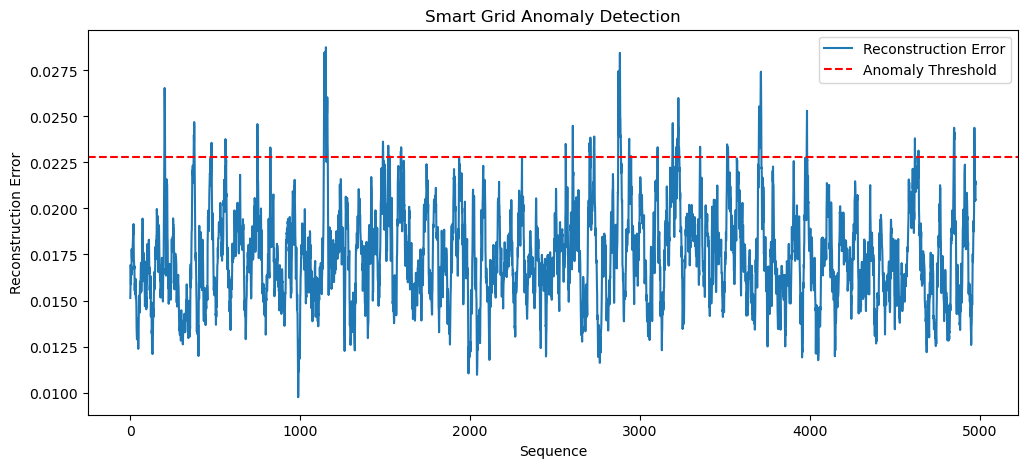

In [17]:
plt.figure(figsize=(12, 5))

plt.plot(errors, label='Reconstruction Error')
plt.axhline(
    y=threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.xlabel('Sequence')
plt.ylabel('Reconstruction Error')
plt.title('Smart Grid Anomaly Detection')
plt.legend()
plt.show()